# CR01 - Scorecard with WOE and logistic regression (German Credit)

Goal: build a classic credit scorecard. WOE binning, logistic regression, points table.
Compare a default `C` with a `C` tuned by 5-fold CV. Report discrimination on a holdout.

Data: German Credit (`kabure/german-credit-data-with-risk`), 1,000 rows. The target
is `Risk` (1 = good). Split is stratified and random (no date column in this dataset).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from credit_core.binning import make_numeric_edges
from credit_core.datasets import load_german
from credit_core.metrics import decile_table
from credit_core.plots import plot_ks, plot_roc, plot_score_distribution
from scorecard_woe.pipeline import CATEGORICAL, FEATURES, NUMERIC, evaluate, fit_scorecard, load_split

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Data and class balance

(1000, 9) good rate: 0.7


,Age,Credit amount,Duration,Job,Housing,Saving accounts,Checking account,Purpose,Sex
0,67,1169,6,2,own,NaN,little,radio/TV,male
1,22,5951,48,2,own,little,moderate,radio/TV,female
2,49,2096,12,1,own,little,NaN,education,male
3,45,7882,42,2,free,little,little,furniture/equipment,male
4,53,4870,24,2,free,little,little,car,male


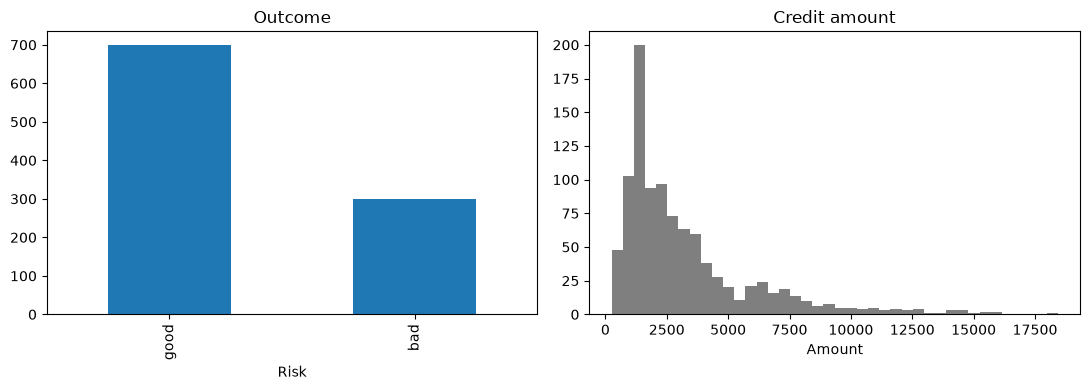

In [2]:
X_all, y_all = load_german()
print(X_all.shape, "good rate:", round(y_all.mean(), 3))
display(X_all.head())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y_all.map({1: "good", 0: "bad"}).value_counts().plot.bar(ax=axes[0], title="Outcome")
axes[1].hist(X_all["Credit amount"], bins=40, color="tab:gray")
axes[1].set(title="Credit amount", xlabel="Amount")
fig.tight_layout()
fig.savefig(FIG / "cr01_eda.png", dpi=120)
plt.show()

## 2. Split and WOE

In [3]:
split = load_split()
print(len(split.X_train), len(split.X_test))
print("edges Credit amount (train):", make_numeric_edges(split.X_train["Credit amount"], 5))

700 300
edges Credit amount (train): [1239.8 1890.6 2829.2 4606.2]


## 3. Fit the baseline (C = 1) and the tuned scorecard (C by CV)

In [4]:
sc_default, _ = fit_scorecard(split, C=1.0)
sc_tuned, C_best = fit_scorecard(split)
print("tuned C:", C_best)

res = pd.DataFrame(
    {
        "model": ["C=1 baseline", f"C={C_best} tuned"],
        "test_auc": [evaluate(sc_default, split)["test"]["auc"], evaluate(sc_tuned, split)["test"]["auc"]],
        "test_gini": [evaluate(sc_default, split)["test"]["gini"], evaluate(sc_tuned, split)["test"]["gini"]],
        "test_ks": [evaluate(sc_default, split)["test"]["ks"], evaluate(sc_tuned, split)["test"]["ks"]],
    }
)
display(res.round(4))

tuned C: 1.0


,model,test_auc,test_gini,test_ks
0,C=1 baseline,0.6684,0.3368,0.3095
1,C=1.0 tuned,0.6684,0.3368,0.3095


## 4. IV ranking

,feature,iv,status
0,Checking account,0.6277,dropped: IV above 0.50
1,Duration,0.2440,kept
2,Saving accounts,0.1902,kept
3,Credit amount,0.1317,kept
4,Purpose,0.1272,kept
5,Age,0.0871,kept
6,Housing,0.0739,kept
7,Job,0.0093,dropped: IV below 0.02


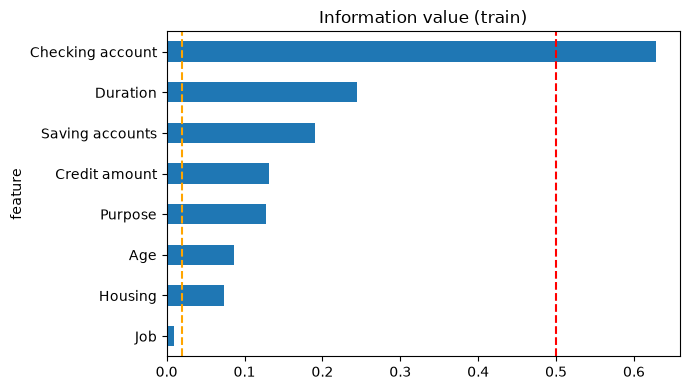

In [5]:
iv = sc_tuned.encoder.iv_table()
display(iv.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
iv.sort_values("iv").plot.barh(x="feature", y="iv", ax=ax, legend=False, title="Information value (train)")
ax.axvline(0.02, color="orange", ls="--")
ax.axvline(0.5, color="red", ls="--")
fig.tight_layout()
fig.savefig(FIG / "cr01_iv.png", dpi=120)
plt.show()

## 5. Points table

In [6]:
pts = sc_tuned.points_table()
display(pts.round(2))

,feature,bin,woe,points
0,intercept,-,NaN,511.51
1,Age,bin0,-0.52,-13.59
2,Age,bin1,-0.11,-2.80
3,Age,bin2,0.14,3.56
4,Age,bin3,0.19,4.97
5,Age,bin4,0.31,8.18
6,Credit amount,bin0,-0.10,-1.64
7,Credit amount,bin1,0.41,6.72
8,Credit amount,bin2,0.21,3.50
9,Credit amount,bin3,0.21,3.50


## 6. Holdout discrimination and plots

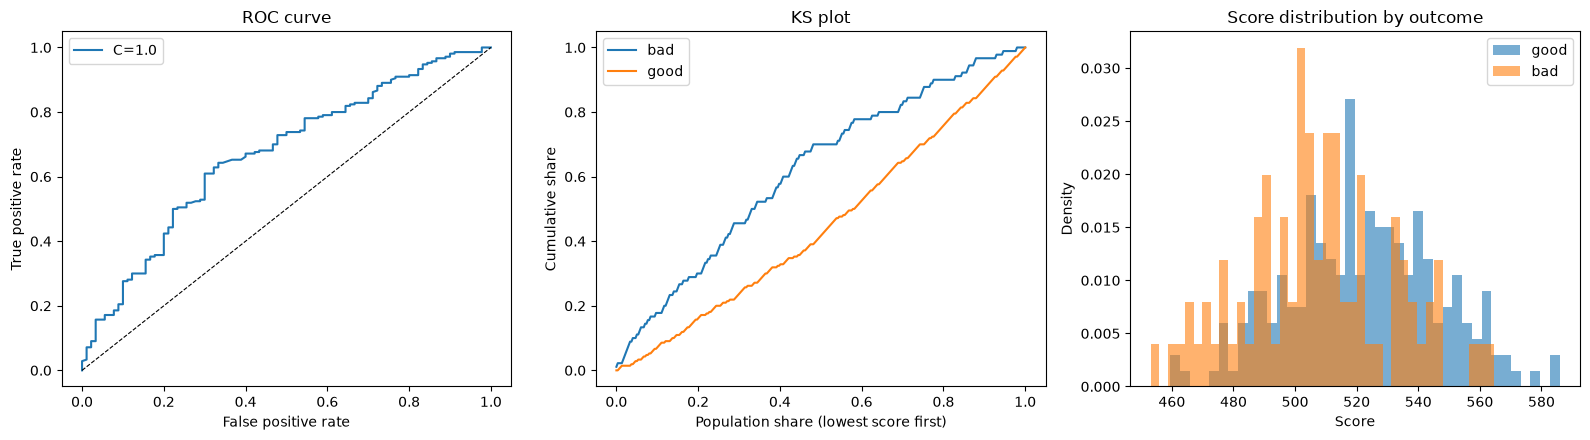

In [7]:
X_te = split.X_test[FEATURES]
p_te = sc_tuned.predict_good(X_te)
s_te = sc_tuned.score(X_te)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_roc(split.y_test, p_te, label=f"C={C_best}", ax=axes[0])
plot_ks(split.y_test, p_te, ax=axes[1])
plot_score_distribution(s_te, split.y_test, ax=axes[2])
fig.tight_layout()
fig.savefig(FIG / "cr01_holdout.png", dpi=120)
plt.show()

In [8]:
decile_table(split.y_test, p_te)

,decile,n,good_rate
0,1,30,0.466667
1,2,30,0.633333
2,3,30,0.533333
3,4,30,0.633333
4,5,30,0.633333
5,6,30,0.766667
6,7,30,0.866667
7,8,30,0.766667
8,9,30,0.800000
9,10,30,0.900000


## 7. Interpretation

Model is a logistic regression on WOE, so each feature has a monotone effect by bin.
`Sex` is not in the model (protected). It is audited in CR03.

In [9]:
print(sc_tuned.reason_codes(X_te.head(3), top=3))

            reason_1         reason_2       reason_3
80   Saving accounts         Duration  Credit amount
157  Saving accounts          Purpose       Duration
65           Purpose  Saving accounts       Duration
